<a href="https://colab.research.google.com/github/eeeewyz/NLP/blob/main/5_form_scrathc_classifier.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Building a Simple Text Classifier in PyTorch

Having explored the foundational concepts of converting text from human language into machine-friendly tensors, you are now ready to apply that knowledge to a practical challenge. You have seen how raw text is tokenized, transformed into numerical IDs, and then represented by meaningful vectors called embeddings that capture semantic relationships between words. This lab will guide you through the process of building a complete text classification pipeline from scratch using PyTorch. The goal is to train a model that can read the title of a recipe and classify it as either fruit-based or vegetable-based.

This hands-on lab will solidify your understanding of the entire workflow, from initial data preparation to final model evaluation. You will put theory into practice and tackle common challenges in natural language processing.

Specifically, in this lab, you'll learn to:

* **Prepare and preprocess raw text data**, which includes cleaning, tokenizing, and building a vocabulary from a training dataset to avoid data leakage.
* **Construct custom PyTorch `Dataset` and `DataLoader` objects** and implement custom `collate` functions to efficiently handle batches of variable-length text sequences.
* **Build, train, and compare multiple model architectures**. This includes an efficient model using `nn.EmbeddingBag` and others that perform manual pooling operations like mean, max, and sum.
* **Address a class imbalance problem** in the dataset by applying class weights to the loss function, a vital technique for training fair and accurate models on skewed data.
* **Evaluate your trained models** to select the best-performing one based on the F1 score and then test its predictive power on new, unseen recipe titles.

为什么用ppoling layer？




假设一条文本经过 Embedding 后：

[batch_size, sequence_length, embedding_dim]

例如：

[32, 20, 100]

表示：

32 条文本
每条最多 20 个词
每个词是 100 维向量

经过 pooling：

[32, 20, 100]
        ↓
[32, 100]

这样每句话都变成一个 100 维向量，后面就可以直接：

Pooling → Linear → 分类结果

使用 pooling 主要有四个原因：

统一输入长度
句子有长有短，pooling 后都变成同样维度的向量。

减少计算量和参数量
不需要把所有词向量全部展开，也不需要使用 LSTM、Transformer 等更复杂模型。

汇总整句话的信息
Mean pooling：保留整句话的平均信息
Max pooling：保留最明显、最强的特征
适合作为简单分类模型的 baseline

原始文本
↓
文本清洗与分词
↓
建立词表
↓
单词转换为 Token ID
↓
Embedding 向量
↓
文本分类模型
↓
预测水果类 / 蔬菜类

Dataset

Dataset 负责定义：

一条数据是什么；
如何取出文本；
如何取出标签；
如何把文本转换成 Token ID。

一条数据可能是：通常是一条菜谱标题，也就是一小句话或一个短语，不一定只是一个单词。
Apple Pie
Fresh Banana Smoothie
Spicy Tomato Soup
Carrot and Onion Salad

text = [15, 3, 21]
label = 0

其中：

0 → fruit
1 → vegetable
DataLoader

DataLoader 负责把多条数据组成一个 batch：

样本1
样本2
样本3
样本4
↓
一个 batch
↓
送入模型

这样模型不需要一次只学习一个样本，也不需要一次加载整个数据集。

## Imports

In [ ]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split

import numpy as np
from sklearn.utils.class_weight import compute_class_weight
from collections import Counter
import re
import pandas as pd

import helper_utils

In [ ]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

Using device: cuda


## The Recipe Dataset

For this lab, you will work with a specially prepared dataset derived from a large collection of recipes. You will load the prepared dataset and get it ready for the modeling process. This involves transforming the recipe titles and labels into a numerical format that a PyTorch model can understand.

**The Food.com Recipe Collection**

Your data originates from the [Food.com Recipes and User Interactions](https://www.kaggle.com/datasets/shuyangli94/food-com-recipes-and-user-interactions) dataset, a vast collection of over 230,000 recipes gathered over 18 years. This rich dataset contains everything from recipe names and ingredients to cooking steps and nutritional information. For the purposes of this lab, a subset of this data has been pre-created, focusing solely on recipes that are either fruit-based or vegetable-based.

**How the Subset Was Created**

The `recipes_fruit_veg.csv` file you'll use was generated by a script that filtered the original dataset. In short, the script performed the following actions:

* It scanned each recipe’s ingredients for a predefined list of common fruit and vegetable keywords.
* To create distinct categories, it only kept recipes that contained fruit keywords but no vegetable keywords, or vice versa.
* Any recipe that contained a mix of both categories, or neither, was excluded.

This process ensures the dataset has two mutually exclusive classes, which is ideal for this classification task. If you're interested, you can explore the exact logic in the `filter_recipe_dataset` function within the `helper_utils.py` file.

* Now, run the cell below to load the dataset. This will read the data from the `recipes_fruit_veg.csv` file into a pandas DataFrame called `df`.

In [ ]:
# Load the filtered dataset into a pandas DataFrame
df = pd.read_csv("recipes_fruit_veg.csv")

### Preparing Inputs and Labels

Begin by inspecting the first ten rows of your DataFrame to understand its structure. This will help you see the raw text data you will be working with.

In [ ]:
# Display the first 10 rows of the DataFrame
df.head(10)

,name,id,minutes,ingredients,steps,category
0,a bit different breakfast pizza,31490,30,"['prepared pizza crust', 'sausage patty', 'egg...","['preheat oven to 425 degrees f', 'press dough...",vegetable
1,all in the kitchen chili,112140,130,"['ground beef', 'yellow onions', 'diced tomato...","['brown ground beef in large pot', 'add choppe...",vegetable
2,alouette potatoes,59389,45,"['spreadable cheese with garlic and herbs', 'n...",['place potatoes in a large pot of lightly sal...,vegetable
3,apple a day milk shake,5289,0,"['milk', 'vanilla ice cream', 'frozen apple ju...","['combine ingredients in blender', 'cover and ...",fruit
4,bananas 4 ice cream pie,70971,180,"['chocolate sandwich style cookies', 'chocolat...","['crumble cookies into a 9-inch pie plate , or...",fruit
5,beat this banana bread,75452,70,"['sugar', 'unsalted butter', 'bananas', 'eggs'...","['preheat oven to 350 degrees', 'butter two 9x...",fruit
6,berry good sandwich spread,109439,5,"['whole berry cranberry sauce', 'sour cream', ...","['in medium size bowl , coarsely mash cranberr...",fruit
7,better than sex strawberries,42198,1460,"['vanilla wafers', 'butter', 'powdered sugar',...",['crush vanilla wafers into fine crumbs and li...,fruit
8,better then bush s baked beans,67547,2970,"['great northern bean', 'chicken bouillon cube...",['in a very large sauce pan cover the beans an...,vegetable
9,chicken lickin good pork chops,63986,500,"['lean pork chops', 'flour', 'salt', 'dry must...","['dredge pork chops in mixture of flour , salt...",vegetable


From the table above, you can see the different columns you have available. For your classification task, **your goal is to predict the category based on the recipe name**.

* **Model Input**: The `name` column will serve as your input feature. This is the text you will train the model to understand.

* **Model Labels**: The `category` column contains the labels ('fruit' or 'vegetable'). However, machine learning models require numerical data, not text. Your next step is to convert these string labels into numbers (e.g., 0 and 1) so the model can process them.

* Perform this conversion by creating a new `label` column and setting the default value of **1 (for 'vegetable')** and then updating the label to **0 for all 'fruit'** recipes.

更准确地说，这一步主要属于数据预处理（data preprocessing）或标签编码（label encoding），不完全是传统意义上的数据清洗。

In [ ]:
# 创建一个新的 'label' 列，并先给所有数据设置默认值 1
# 这里规定：1 表示 vegetable（蔬菜）
df['label'] = 1

# df['category'] == 'fruit'：
# 判断每一行的 category 是否等于 'fruit'，返回一组 True/False
#
# df.loc[行条件, 列名]：
# 根据条件选中指定的行和列
#
# 将 category 为 fruit（水果）的行，其 label 修改为 0
# 这里规定：0 表示 fruit（水果）
df.loc[df['category'] == 'fruit', 'label'] = 0

# 显示 DataFrame 的前 5 行
# 用来检查新创建的 label 列是否正确
df.head()

,name,id,minutes,ingredients,steps,category,label
0,a bit different breakfast pizza,31490,30,"['prepared pizza crust', 'sausage patty', 'egg...","['preheat oven to 425 degrees f', 'press dough...",vegetable,1
1,all in the kitchen chili,112140,130,"['ground beef', 'yellow onions', 'diced tomato...","['brown ground beef in large pot', 'add choppe...",vegetable,1
2,alouette potatoes,59389,45,"['spreadable cheese with garlic and herbs', 'n...",['place potatoes in a large pot of lightly sal...,vegetable,1
3,apple a day milk shake,5289,0,"['milk', 'vanilla ice cream', 'frozen apple ju...","['combine ingredients in blender', 'cover and ...",fruit,0
4,bananas 4 ice cream pie,70971,180,"['chocolate sandwich style cookies', 'chocolat...","['crumble cookies into a 9-inch pie plate , or...",fruit,0


With the numerical `label` column now ready, you can extract the data into its final format.

* Create two separate Python lists:
    * `texts`: A list containing the recipe names from the `name` column.
    * `labels`: A list containing the numerical labels (0 or 1) from the `label` column.

这部分代码是在进行数据清洗 + 提取模型需要的输入和标签。

In [ ]:
# 删除 name 列中存在缺失值（NaN）的行
# 因为没有菜谱名称的数据无法作为文本输入模型
df_clean = df.dropna(subset=['name'])

# 从清洗后的 DataFrame 中取出 name 列
# 使用 tolist() 将 Pandas Series 转换成 Python 列表
# texts 中保存所有菜谱名称，作为模型的文本输入
texts = df_clean['name'].tolist()

# 从清洗后的 DataFrame 中取出 label 列
# 转换成 Python 列表
# labels 中保存每个菜谱名称对应的数字标签
labels = df_clean['label'].tolist()

* Run the next cell to see a breakdown of the samples you'll be working with.
    * **Note**: Pay close attention to the output. You'll notice there are significantly fewer fruit recipes than vegetable recipes. This is a common issue known as data imbalance, and it's important to keep this in mind as you will address it later in the notebook.

In [ ]:
# Verify the final dataset size and the class distribution.
print(f"Total samples for classification:\t{len(texts)}")
print(f"Fruit recipes:\t\t\t\t{labels.count(0)}, {round(labels.count(0)/(labels.count(0) + labels.count(1)) *100,1)} %")
print(f"Vegetable recipes:\t\t\t{labels.count(1)}, {round(labels.count(1)/(labels.count(0) + labels.count(1)) *100,1)} %")

Total samples for classification:	142915
Fruit recipes:				29148, 20.4 %
Vegetable recipes:			113767, 79.6 %


#### Previewing the Input and Labels

Your data is now structured with the `name` column as the model's input and the `label` column as its output.

* Run the cell below to review a random sample of these training pairs.

In [ ]:
# Set the number of random samples to display.
num_samples = 10

# Display a sample of name and label pairs.
display(df[['name', 'label']].sample(num_samples, random_state=25).style.hide(axis="index"))

name,label
cajun tomato gravy,1
scallop soup,1
chicken piccata light,0
bombay kidney beans,1
surefire siu mai dim sum,1
linguini alla critzos,1
zuppa toscana,1
maine blueberry cake,0
lemon cream cheese coffee cake,0
sweet smoky salmon kabobs,1


## Splitting the Raw Data

To accurately judge your model's performance, you need to test it on data it has **never seen before**. This means your first step before any text processing or vocabulary building is to separate your raw texts and labels lists into two distinct groups.

The reason you do this now is to prevent **data leakage**. If you were to build your vocabulary from the **entire** dataset, the model would have already been exposed to the words in your validation data. This would not be a fair test of how it performs on new, real-world information.

By splitting the raw data first, you can build the vocabulary using only the words from one group (the training data). The other group remains completely untouched, ensuring it is a truly "unseen" set of data for your final evaluation. You perform this division as a clean, preliminary step before any PyTorch specific formatting.

* Use the <code>[train_test_split()](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html)</code> function from **scikit-learn** to handle this.
    * `texts`: The list of recipe titles you want to split.
    * `labels`: The list of corresponding labels for each recipe title.
    * `test_size=0.2`: Specifies that 20% of the data should be used for the validation set.
    * `stratify=labels`: Ensures the training and validation sets have the same class proportions as the original dataset.

词汇表只从训练集建立，然后用这个固定词汇表处理验证集，检查模型能否根据已经学到的词和规律，对没见过的菜谱名称进行正确分类。

In [ ]:
train_texts, val_texts, train_labels, val_labels = train_test_split(
    texts,
    labels,
    test_size=0.2,
    stratify=labels
)

# Print the number of samples in each set to verify the split.
print(f"Training samples: {len(train_texts)}")
print(f"Validation samples: {len(val_texts)}")

Training samples: 114332
Validation samples: 28583


### Text Preprocessing and Vocabulary Building

With your data now split into separate groups, it's time to convert the recipe titles into a numerical format that your model can understand. This involves cleaning the text and then building a vocabulary to map each unique word to a number.

* Define the `preprocess_text` function and apply it to your recipe titles.
    * It takes a raw text string as its input, cleans the text by converting it to lowercase, and removes any characters that are not letters or spaces.
    * It then tokenizes the string by splitting it into a list of individual words.

In [ ]:
def preprocess_text(text):
    """Cleans and tokenizes a raw text string.

    Args:
        text (str): The raw text to be processed.

    Returns:
        list: A list of cleaned words (tokens).
    """
    # Convert the entire text to lowercase.
    text = text.lower()
    # Remove all characters that are not letters or whitespace.
    text = re.sub(r'[^a-zA-Z\s]', '', text)
    # Split the cleaned string into a list of words.
    words = text.split()

    return words

In [ ]:
# Preprocess the training and validation texts separately.
processed_train_texts = [preprocess_text(text) for text in train_texts]
processed_val_texts = [preprocess_text(text) for text in val_texts]

* Define the `Vocabulary` class, which creates and manages the mapping between words and unique numerical IDs.
    * `__init__`: Initializes the vocabulary with special tokens for padding (`<pad>`) and unknown words (`<unk>`). It also sets a minimum frequency (`min_freq`) for a word to be included.
    * `build_vocab`: Scans all the processed texts, counts the frequency of every word, and adds words that meet the `min_freq` threshold to the vocabulary mapping.
    * `encode`: Takes a list of words and converts it into the corresponding list of numerical IDs. It uses the `<unk>` token's ID for any word it doesn't recognize.
    * `__len__`: Allows you to find the total number of unique items in the vocabulary by calling `len()` on the object.

In [ ]:
class Vocabulary:
    """Builds and manages a word-to-index vocabulary from text.

    Attributes:
        word2idx (dict): Maps words to unique integers.
        idx2word (dict): Maps integers back to words.
        min_freq (int): Minimum word frequency for inclusion.
    """
    def __init__(self, min_freq=1):
        """Initializes the vocabulary.

        Args:
            min_freq (int): Minimum word frequency to be included.
        """
        # Mappings for word-to-index and index-to-word with special tokens.
        self.word2idx = {'<pad>': 0, '<unk>': 1}
        self.idx2word = {0: '<pad>', 1: '<unk>'}
        self.min_freq = min_freq

    def build_vocab(self, texts):
        """Builds the vocabulary from a corpus of tokenized texts.

        Args:
            texts (list of list of str): A corpus of tokenized sentences.
        """
        # Count the frequency of all words in the corpus.
        word_counts = Counter(word for text in texts for word in text)

        # Add words to the vocabulary if they meet the minimum frequency.
        for word, count in word_counts.items():
            if count >= self.min_freq:
                idx = len(self.word2idx)
                self.word2idx[word] = idx
                self.idx2word[idx] = word

    def encode(self, text):
        """Converts a tokenized text to a sequence of indices.

        Args:
            text (list of str): Tokenized text to encode.

        Returns:
            list of int: Sequence of corresponding indices.
        """
        # Use the <unk> token for words not in the vocabulary.
        return [self.word2idx.get(word, self.word2idx['<unk>']) for word in text]

    def __len__(self):
        """Returns the vocabulary size."""
        return len(self.word2idx)

* Create a new vocabulary object to manage your word-to-number mappings.
    * `min_freq=2`: Ensures that only words appearing at least twice in your texts will be added to the vocabulary.

In [ ]:
vocab = Vocabulary(min_freq=2)

* Execute the main vocabulary building process. **The vocabulary will be built using only the training data**.
    * It scans all of the `processed_texts`, counts the frequency of every word, and creates the final word-to-number mapping for all words that meet the `min_freq` rule.

In [ ]:
# Build the vocabulary using ONLY the processed training texts.
vocab.build_vocab(processed_train_texts)

In [ ]:
print("Number of words in the vocabulary:", len(vocab))

Number of words in the vocabulary: 8920


* Use the `vocab.encode()` method to convert your preprocessed training texts into lists of numerical IDs.
* Repeat the exact same process for your validation texts, using the same vocabulary you built from the training data.

In [ ]:
# Encode both the training and validation texts using the vocabulary.
indexed_train_texts = [vocab.encode(text) for text in processed_train_texts]
indexed_val_texts = [vocab.encode(text) for text in processed_val_texts]

### Preparing Data for Training

Now that you have separate, encoded lists for your training and validation data, you can create custom PyTorch `Dataset` objects for each to encapsulate your "indexed texts" and "labels".

#### Building Your Custom `TextDataset`

* Define a custom dataset by inheriting from PyTorch's `Dataset` class.
    * `__init__`: Stores the lists of indexed texts and numerical labels. It also creates a `.classes` attribute by finding and sorting the unique values from the labels list.
    * `__len__`: Returns the total number of samples (the length of your texts list) in the dataset.
    * `__getitem__`: Retrieves a single data sample. Given an index idx, it fetches the corresponding text and label, converts them into PyTorch tensors, and returns them in a dictionary.

Vocabulary 类负责建立词典、过滤低频词、处理未知词，并把文本转换为模型可读取的整数 ID。

__getitem__

根据索引取出一条样本：

dataset[0]

可能返回：

{
    "text": tensor([2, 4, 5]),
    "label": tensor(0)
}

也就是说：

第 0 条文本： [2, 4, 5]
第 0 条标签： 0

1. 为什么要建立 sample？

因为模型训练时，一次需要拿到一条完整样本：

一条文本 + 这条文本对应的标签

例如原始数据是：

self.texts = [
    [2, 5, 8],
    [4, 3],
    [7, 9, 1]
]

self.labels = [0, 1, 0]

那么：

dataset[0]

应该同时拿到：

文本：[2, 5, 8]
标签：0

所以用字典把二者装在一起：

sample = {
    'text': ...,
    'label': ...
}

最终返回：

{
    'text': tensor([2, 5, 8]),
    'label': tensor(0)
}

这样文本和标签就不会分开。

 为什么要使用 torch.tensor()？

因为原来的数据通常是 Python 列表或普通整数：

[2, 5, 8]

但 PyTorch 模型通常不能直接处理普通 Python 列表，它需要 Tensor：

tensor([2, 5, 8])

所以：

torch.tensor(self.texts[idx])

就是把：

[2, 5, 8]

转换为：

tensor([2, 5, 8])

In [ ]:
class TextDataset(Dataset):
    """
    自定义的 PyTorch Dataset。

    用于保存：
    1. 数字化后的文本序列
    2. 每条文本对应的标签

    定义之后，可以交给 DataLoader 进行分批读取。
    """

    def __init__(self, texts, labels):
        """
        初始化数据集。

        参数：
            texts:
                数字化后的文本序列集合。

                例如：
                [
                    [2, 5, 8],
                    [4, 3],
                    [7, 9, 1]
                ]

            labels:
                每条文本对应的类别标签。

                例如：
                [0, 1, 0]
        """



        #右边传进来的 texts  →  保存到对象自己的 self.texts
        # 图片里的 texts 已经是转换好的数字序列，例如：[2, 5, 8] self.texts = texts 只是把这些数字序列保存起来。
        #右边传进来的 labels →  保存到对象自己的 self.labels

        # 保存所有文本序列
        self.texts = texts

        # 保存所有标签
        self.labels = labels

        # 找出数据集中所有不重复的类别，并进行排序
        #
        # 例如：
        # labels = [1, 0, 1, 0]
        #
        # set(labels)           -> {0, 1}
        # list(set(labels))     -> [0, 1]
        # sorted(...)           -> [0, 1]
        #
        # 最终：
        # self.classes = [0, 1]
        self.classes = sorted(list(set(labels)))

    def __len__(self):
        """
        返回数据集中的样本总数。

        当调用：
            len(dataset)

        Python 实际会调用这个方法。
        """

        # 文本数量就是样本数量
        return len(self.texts)

    def __getitem__(self, idx):
        """
        这里输入的是索引：
        idx = 0

        函数内部再根据这个索引取数据：

        self.texts[0]
        self.labels[0]

        然后组合成：

        sample = {
            "text": tensor([2, 5, 8]),
            "label": tensor(0)
        }

        最终返回：

        return sample


        参数：
            idx:
                要读取的数据索引。

        返回：
            一个字典，包含：
            - text：文本的整数序列张量
            - label：类别标签张量
        """

        sample = {
            # 取出第 idx 条数字化文本，并转换成整数张量

            # nn.Embedding 要求输入必须是整数类型 LongTensor。
            # 主要做两件事：
            # 把 Python 数字或数字列表转换成 PyTorch Tensor
            # 用 dtype=torch.long 指定数据类型为 64 位整数

            'text': torch.tensor(
                self.texts[idx],
                dtype=torch.long
            ),

            # 取出第 idx 条文本对应的标签，并转换成整数张量
            #
            # 使用 torch.long 通常是因为：
            # CrossEntropyLoss 要求类别标签是整数类型。
            'label': torch.tensor(
                self.labels[idx],
                dtype=torch.long
            )
        }

        return sample

* Create instances of your `TextDataset` for training and validation sets.

In [ ]:
# Create the training and validation datasets directly from the split data.
train_dataset = TextDataset(indexed_train_texts, train_labels)
val_dataset = TextDataset(indexed_val_texts, val_labels)

# Print the number of samples in each set to verify.
print(f"Training samples:   {len(train_dataset)}")
print(f"Validation samples: {len(val_dataset)}")

Training samples:   114332
Validation samples: 28583


#### The Collate Function and DataLoaders

In all of your previous modules on computer vision, you saw that every image was preprocessed into a **fixed**, **uniform size** (e.g., 224x224 pixels). Since each image tensor had the exact same dimensions, the `DataLoader` could easily combine them into a single batch.

Text, however, is naturally variable. For example:

* `"apple pie"` becomes a tensor of length 2.

* `"roasted broccoli and garlic"` becomes a tensor of length 4.

This is where you'll run into an issue with the `DataLoader`'s **default configuration**. By default, it tries to create a batch by stacking the individual tensors. This operation will fail because your text tensors have different lengths, and they can't be stacked into a single, uniform tensor. This is the new challenge you must solve.

**The Solution: The `collate_fn` Parameter**

To solve this, you'll use an optional but powerful parameter of the `DataLoader` class: `collate_fn`.

This parameter lets you provide your own custom function that defines exactly how to take a list of samples from your `Dataset` and combine them into a single batch. Instead of using the default behavior, the `DataLoader` will execute your custom logic.

```python
DataLoader(dataset=...,
           batch_size=...,
           shuffle=...,
           collate_fn=... # <-- Your custom function goes here
          )
```

You are essentially telling the `DataLoader`, "Don't use your default stacking method; use my specific instructions to form a batch."

This practice of using a `collate_fn` is also the standard and most efficient method. While you could pad all sentences from the start, that approach is inefficient, leading to **significant memory and computational waste**. By using a `collate_fn` to perform "dynamic padding," each batch is only padded to the length of the longest sentence within that batch, which saves resources and speeds up training.

You will define two such functions, one for each of the model architectures that will be covered in the next section.

* First, define `collate_batch_embeddingbag`, which takes a list of samples and prepares a batch specifically formatted for PyTorch's efficient `nn.EmbeddingBag` layer (this will be covered in the next section).
    * It first extracts all the labels and text tensors from the batch.
    * It then creates a single, long 1D tensor, `flattened_text`, by concatenating all the individual text tensors together.
    * It computes an `offsets` tensor. This tensor marks the starting index of each original recipe title within the `flattened_text` tensor.
    * Finally, it returns the flattened text, the offsets, and the labels, all moved to the active device (e.g., your GPU).

collate_fn 是干什么的？

collate_fn 就是让你告诉 DataLoader：

“这些不同长度的样本，不要按默认方法拼，我自己定义怎么拼。”

例如：

DataLoader(
    dataset=dataset,
    batch_size=4,
    shuffle=True,
    collate_fn=collate_batch_embeddingbag
)

这里：

collate_fn=collate_batch_embeddingbag

意思就是：

当 DataLoader 拿到 4 条 sample 后，调用这个函数把它们整理成一个 batch。

 collate_batch_embeddingbag 为什么不是 padding？

这里用的是：

nn.EmbeddingBag

它有一个很特别的输入方式。

它不要求你把每句话 pad 成一样长，而是：

把所有句子的 token 全部接成一条长的一维 Tensor，然后告诉它每句话从哪里开始。

例如三句话：

text1 = tensor([2, 5])
text2 = tensor([4, 7, 9, 3])
text3 = tensor([8, 6, 1])


先拼起来：

[2, 5, 4, 7, 9, 3, 8, 6, 1]


那怎么知道每句话在哪里？

这就是：offsets的作用。
每句话起始位置：

句子1从 0 开始
句子2从 2 开始
句子3从 6 开始

所以：

offsets = tensor([0, 2, 6])

和刚才学的 __getitem__() 有什么关系？？
__getitem__()
    ↓
一条 sample

很多 sample
    ↓
collate_fn
    ↓
一个 batch

batch
 ↓
取出 labels
 ↓
取出 texts
 ↓
计算每条 text 长度
 ↓
算 offsets
 ↓
把所有 text 拼成 flattened_text
 ↓
返回：
flattened_text + offsets + labels

比如原来的 batch 是：

batch = [
    {'text': tensor([2, 5]),    'label': 0},
    {'text': tensor([4, 7, 9]), 'label': 1},
    {'text': tensor([8, 6]),    'label': 0}
]

执行：

texts = [
    item['text'] for item in batch
]

以后得到：

texts = [
    tensor([2, 5]),
    tensor([4, 7, 9]),
    tensor([8, 6])
]

EmbeddingBag 方法的区别

方法1：EmbeddingBag

输入：

flattened_text

[2,5,4,7,9,8,6]

加：

offsets

[0,2,5]

告诉模型：

第1句:
0-1

第2句:
2-4

第3句:
5-6

优点：

不需要 padding
节省空间
EmbeddingBag 内部处理平均池化





方法2：Padding

输入：

[
[2,5,0],
[4,7,9],
[8,6,0]
]

优点：

普通神经网络容易处理
Transformer 必须这样
可以使用 mask

缺点：

多出来的 0 浪费计算

总结一句：

collate_batch_manual()

做的事情：

不同长度文本
        |
        ↓
找到最长长度 max_len
        |
        ↓
创建全0矩阵(batch_size,max_len)
        |
        ↓
把每句话复制进去
        |
        ↓
短句后面补0
        |
        ↓
得到规则二维Tensor

最终从：

[
 tensor([2,5]),
 tensor([4,7,9]),
 tensor([8,6])
]

变成：

tensor([
 [2,5,0],
 [4,7,9],
 [8,6,0]
])

这就是 padding 的核心思想。

In [ ]:
def collate_batch_embeddingbag(batch):
    """
    将一个 batch 的多条样本整理成 nn.EmbeddingBag 需要的格式。

    参数:
        batch:
            一个列表，里面包含多条 Dataset 返回的 sample。
            例如：
            [
                {'text': tensor([2, 5]), 'label': tensor(0)},
                {'text': tensor([4, 7, 9]), 'label': tensor(1)},
                {'text': tensor([8, 6]), 'label': tensor(0)}
            ]

    返回:
        flattened_text:
            把所有文本 token 拼成的一条长 1D Tensor。

        offsets:
            记录每条文本在 flattened_text 中的起始位置。

        labels:
            当前 batch 中所有样本对应的标签。
    """

    # 1. 从 batch 中取出每条样本的 label
    #
    # 假设：
    # batch 中的 label 分别是：
    # 0, 1, 0
    #
    # 那么最后：
    # labels = tensor([0, 1, 0])
    labels = torch.tensor(
        [item['label'] for item in batch]
    )


    # 2. 从 batch 中取出每条样本的 text
    #
    # 例如：
    # texts = [
    #     tensor([2, 5]),
    #     tensor([4, 7, 9]),
    #     tensor([8, 6])
    # ]
    #
    # 注意：
    # 每条文本长度可以不同
    texts = [
        item['text'] for item in batch
    ]


    # 3. 计算每条文本的长度
    #
    # 例如：
    # len([2,5])     = 2
    # len([4,7,9])   = 3
    # len([8,6])     = 2
    #
    # 得到：
    # [2, 3, 2]
    #
    # 前面再加一个 0：
    # [0, 2, 3, 2]
    #
    # 这个 0 是因为第一条文本一定从位置 0 开始
    offsets = [0] + [
        len(text) for text in texts
    ]


    # 4. 计算每条文本在 flattened_text 中的起始位置
    #
    # 当前：
    # offsets = [0, 2, 3, 2]
    #
    # offsets[:-1]
    # 去掉最后一个元素：
    # [0, 2, 3]
    #
    # 然后 cumsum（cumulative sum，累积求和）：
    #
    # [0,
    #  0+2,
    #  0+2+3]
    #
    # 得到：
    # tensor([0, 2, 5])
    #
    # 意思是：
    # 第1条文本从位置 0 开始
    # 第2条文本从位置 2 开始
    # 第3条文本从位置 5 开始
    offsets = torch.tensor(
        offsets[:-1]
    ).cumsum(dim=0)


    # 5. 把所有不同长度的文本首尾连接
    #   原来的：

    # [
    #     tensor([2, 5]),
    #     tensor([4, 7, 9]),
    #     tensor([8, 6])
    # ]

    # 拼成：

    # flattened_text =
    # tensor([2, 5, 4, 7, 9, 8, 6])

    # EmbeddingBag 会结合 offsets，
    # 知道哪些 token 属于哪一条文本
    flattened_text = torch.cat(texts)


    # 6. 返回 EmbeddingBag 模型需要的三个 Tensor
    #
    # flattened_text:
    # 所有 token 拼起来
    #
    # offsets:
    # 每条文本的开始位置
    #
    # labels:
    # 每条文本的类别标签
    #
    # .to(device):
    # 把 Tensor 移动到当前计算设备
    # 例如 CPU 或 GPU
    return (
        flattened_text.to(device),
        offsets.to(device),
        labels.to(device)
    )

* Next, define `collate_batch_manual`, which prepares a batch using the more common technique of **padding**.
    * It starts by extracting all the labels and text tensors from the batch.
    * It then finds the length of the longest sequence (`max_len`) **within the current batch**.
    * A new tensor of zeros, `padded_texts`, is created with the shape `(batch_size, max_len)`. This acts as a template for the batch.
    * It then loops through and copies each text sequence into the `padded_texts` tensor, leaving the remaining space as zero-padding for shorter sequences.
    * Finally, it returns the single, rectangular `padded_texts` tensor and the `labels` tensor, both moved to the active device.

In [ ]:
def collate_batch_manual(batch):
    """
    自定义 batch 处理函数。

    DataLoader 会自动调用这个函数，
    将多个 Dataset 样本组合成一个 batch。

    主要任务：
    1. 提取文本和标签
    2. 找到当前 batch 最大文本长度
    3. 对短文本补 <PAD> (这里用0表示)
    4. 返回统一大小的 Tensor
    """

    # ----------------------------------------
    # 1. 提取每个样本的 label
    # ----------------------------------------

    # batch 是 DataLoader 取出的多个样本组成的 list
    #
    # 例如：
    #
    # batch = [
    #   {'text': tensor([2,5,8]), 'label': tensor(0)},
    #   {'text': tensor([4,7]), 'label': tensor(1)}
    # ]
    #
    # 这里取出所有 label：

    labels = torch.tensor(
        [item['label'] for item in batch]
    )

    # 得到：
    #
    # tensor([0,1])
    #
    # 表示这个 batch 中每个文本对应的类别


    # ----------------------------------------
    # 2. 提取每个文本序列
    # ----------------------------------------

    texts = [
        item['text']
        for item in batch
    ]

    # 例如：
    #
    # [
    #   tensor([2,5,8]),
    #   tensor([4,7]),
    #   tensor([9,1,3,6])
    # ]


    # ----------------------------------------
    # 3. 找当前 batch 中最长文本长度
    # ----------------------------------------

    max_len = max(
        len(text)
        for text in texts
    )

    # 例如：
    #
    # 长度分别：
    # 3
    # 2
    # 4
    #
    # max_len = 4
    #
    # 注意：
    # 这里不是整个数据集最大长度，
    # 而是当前这个 batch 内的最大长度。


    # ----------------------------------------
    # 4. 创建 padding 后的空 Tensor
    # ----------------------------------------

    padded_texts = torch.zeros(
        len(texts),
        max_len,
        dtype=torch.long
    )

    # 假设：
    #
    # batch 有3个句子
    # 最大长度4
    #
    # 创建：
    #
    # tensor([
    #   [0,0,0,0],
    #   [0,0,0,0],
    #   [0,0,0,0]
    # ])
    #
    # 这里0代表 <PAD>


    # ----------------------------------------
    # 5. 把原始文本复制到 padding Tensor 中
    # ----------------------------------------

    for i, text in enumerate(texts):

        padded_texts[
            i,
            :len(text)
        ] = text


    # 举例：
    #
    # 原始：
    #
    # text1 = [2,5,8]
    # text2 = [4,7]
    # text3 = [9,1,3,6]
    #
    # 经过循环：
    #
    # padded_texts =
    #
    # [
    #   [2,5,8,0],
    #   [4,7,0,0],
    #   [9,1,3,6]
    # ]


    # ----------------------------------------
    # 6. 移动到 GPU / CPU 并返回
    # ----------------------------------------

    return (
        padded_texts.to(device),
        labels.to(device)
    )

* Create two `DataLoader` instances, `train_loader_embag` and `val_loader_embag`.
    * `collate_fn=collate_batch_embeddingbag`: Passing your custom `collate_batch_embeddingbag` function to both Dataloaders.

In [ ]:
# 设置每个 batch 中包含的样本数量
# 即模型每次训练输入多少条文本
batch_size = 32


# 创建训练集 DataLoader
#
# DataLoader 的作用：
# 1. 从 Dataset 中按 batch 读取数据
# 2. 调用 collate_fn 对一个 batch 进行格式整理
# 3. 将整理后的数据送入模型训练

train_loader_embag = DataLoader(
    train_dataset,

    # 每次取 32 条训练样本
    batch_size=batch_size,

    # 训练时打乱数据顺序
    # 防止模型学习到数据排列规律
    # 增强模型泛化能力
    shuffle=True,

    # 指定 batch 数据的整理方式
    collate_fn=collate_batch_embeddingbag
)


# 创建验证集 DataLoader

val_loader_embag = DataLoader(
    val_dataset,

    # 验证时同样每次处理32条数据
    batch_size=batch_size,

    # 验证阶段不需要随机打乱数据
    #
    # 因为验证只用于：
    # 1. 模型预测
    # 2. 计算 accuracy / loss
    #
    # 不更新模型参数
    shuffle=False,

    # 验证数据也需要转换成 EmbeddingBag 的输入格式
    collate_fn=collate_batch_embeddingbag
)

* Now, create two `DataLoader` instances, `train_loader_manual` and `val_loader_manual`.
    * `collate_fn=collate_batch_manual`: Passing your custom `collate_batch_manual` function to both Dataloaders.

In [ ]:
# Create the DataLoader for the training set with `collate_batch_manual`
train_loader_manual = DataLoader(train_dataset,
                                 batch_size=batch_size,
                                 shuffle=True,
                                 collate_fn=collate_batch_manual
                                )

# Create the DataLoader for the validation set with `collate_batch_manual`
val_loader_manual = DataLoader(val_dataset,
                               batch_size=batch_size,
                               shuffle=False,
                               collate_fn=collate_batch_manual
                              )

## Model Architectures: EmbeddingBag vs. Manual Pooling

So far, you've completed the entire data pipeline: you've loaded, cleaned, and tokenized the text; built a numerical vocabulary; and prepared `DataLoaders` to feed batches to a model. Now, it's time to design the models that will learn from this data.

You're going to build and compare four different model architectures. The models start by converting word indices into dense embedding vectors, but they differ in the next step: how they aggregate the embeddings from a variable-length sentence into a single, fixed-size vector that can be used for classification.

1. The first model uses `nn.EmbeddingBag`, a highly efficient, built-in PyTorch layer that performs a **mean** aggregation in one go.

2. The next models use a **manual pooling** approach.  We will use three approaches where we will aggregate the embeddings by the **mean**, **max**, and **sum**.

By building and testing these, you'll discover which of the new strategies performs better for this specific task.

### EmbeddingBagClassifier

Your first model, the `EmbeddingBagClassifier`, is a simple but powerful architecture built around PyTorch's efficient `nn.EmbeddingBag` layer.

* `__init__`: Defines the three layers of the model:
    * <code>[nn.EmbeddingBag](https://docs.pytorch.org/docs/stable/generated/torch.nn.EmbeddingBag.html)</code>: This is the core of the model. In a single step, this layer takes your token IDs and their corresponding offsets and computes a fixed-size vector for each recipe title by averaging its word embeddings.
    * `nn.Dropout`: This is a standard regularization layer that helps prevent the model from overfitting.
    * `nn.Linear`: This is the final, fully connected classification layer that takes the vector from the embedding bag and outputs the raw scores for each class ('fruit' or 'vegetable').
* The `forward` method defines the actual data flow. The data passes through the layers in this order: `EmbeddingBag` → `Dropout` → `Linear`.

embedded
   ↓
self.fc(embedded)
   ↓
Linear forward
   ↓
W × embedded + b
   ↓
logits
   ↓
return logits

embedded = self.embedding_bag(text, offsets)

这里的 embedded 不是 forward 的输入参数，而是 forward 内部新创建的一个变量。

你可以把它理解成：

def forward(self, text, offsets=None):

    # 用输入参数 text 和 offsets 做一次计算
    embedded = self.embedding_bag(text, offsets)

    # embedded 是上一步计算出来的中间结果
    embedded = self.dropout(embedded)

    # 再把这个中间结果传给 fc
    output = self.fc(embedded)

    return output

self.fc = nn.Linear(embedding_dim, num_classes)

这里的两个参数是在创建这层 Linear 时配置它的结构：

embedding_dim：输入特征维度，例如 64
num_classes：输出特征维度，例如 2

比如：

self.fc = nn.Linear(64, 2)

意思是：

创建一个“64维输入 → 2维输出”的线性层。

此时只需要传入真正的数据：

embedded

比如：

embedded.shape = [32, 64]

表示：

32 个样本
每个样本 64 维

那么之前创建好的：

self.fc = nn.Linear(64, 2)

已经知道：

“我接受64维输入，并且要输出2维。”

所以调用时不用再写：

self.fc(embedded, 64, 2)   # ❌ 不需要

只需要：

self.fc(embedded)          # ✅

它内部自动计算：

Y=XWT+b


第一次：创建机器
nn.Linear(64, 2)
          ↑   ↑
       输入维度 输出维度
       这些配置已经记住了

第二次：使用机器
self.fc(embedded)
        ↑
      只放数据

In [ ]:
class EmbeddingBagClassifier(nn.Module):
    """
    使用 nn.EmbeddingBag 实现的简单文本分类模型。

    整体流程：
    文本 token id
        ↓
    EmbeddingBag
    （查找每个词的 embedding，并对一句话中的所有词向量取平均）
        ↓
    Dropout
    （随机丢弃部分特征，防止过拟合）
        ↓
    Linear
    （将句子的 embedding 映射到不同类别）
        ↓
    logits
    """

    def __init__(self, vocab_size, embedding_dim, num_classes):
        """
        Args:
            vocab_size:
                词汇表大小。
                例如词汇表中有 10,000 个 token，
                vocab_size = 10000。

            embedding_dim:
                每个单词 embedding 向量的维度。
                例如 embedding_dim = 100，
                每个单词都会被表示成一个 100 维向量。

            num_classes:
                最终分类类别数量。
                例如：
                    fruit / vegetable
                两个类别：
                    num_classes = 2
        """

        # 初始化父类 nn.Module
        super().__init__()

        # ---------------------------------------------------------
        # 1. EmbeddingBag 层
        # ---------------------------------------------------------
        # 建立一个 embedding matrix：
        #
        # shape:
        #     [vocab_size, embedding_dim]
        #
        # 例如：
        #     vocab_size = 10000
        #     embedding_dim = 100
        #
        # embedding matrix:
        #     [10000, 100]
        #
        # 每一个 token id 对应其中一行 embedding。
        #
        # 与普通 nn.Embedding 不同：
        #
        # nn.Embedding:
        #     返回每一个单词自己的 embedding
        #
        # nn.EmbeddingBag(mode='mean'):
        #     直接把一句话中所有单词的 embedding 求平均，
        #     得到一个代表整句话的向量。
        #
        self.embedding_bag = nn.EmbeddingBag(
            vocab_size,
            embedding_dim,
            mode='mean'
        )

        # ---------------------------------------------------------
        # 2. Dropout 层
        # ---------------------------------------------------------
        # 训练时随机把 50% 的特征置为 0，
        # 降低模型过拟合的风险。
        #
        # 注意：
        # model.train() 时启用
        # model.eval() 时自动关闭
        #
        self.dropout = nn.Dropout(0.5)

        # ---------------------------------------------------------
        # 3. 全连接分类层
        # ---------------------------------------------------------
        # 输入：
        #     每句话的 embedding
        #     shape = [batch_size, embedding_dim]
        #
        # 输出：
        #     每个类别对应一个分数 logits
        #     shape = [batch_size, num_classes]
        #nn.Linear(输入维度, 输出维度)
        self.fc = nn.Linear(
            embedding_dim,
            num_classes
        )

    def forward(self, text, offsets=None):
        """
        定义模型前向传播过程。

        Args:
            text:
                一个 1D Tensor，
                保存当前 batch 中所有句子的 token id，
                并且已经被拼接(flatten)到一起。

                例如原来有三句话：

                    sentence1 = [3, 5, 8]
                    sentence2 = [2, 7]
                    sentence3 = [4, 6, 9, 1]

                flatten 后：

                    text =
                    [3, 5, 8, 2, 7, 4, 6, 9, 1]

            offsets:
                每句话在 text 中的起始位置。

                上面的例子：

                    offsets = [0, 3, 5]

                表示：

                    第1句话从 text[0] 开始
                    第2句话从 text[3] 开始
                    第3句话从 text[5] 开始

        Returns:
            logits:
                每句话对应每个类别的原始预测分数。

                shape:
                    [batch_size, num_classes]
        """

        # ---------------------------------------------------------
        # Step 1：把 token id 转换成句子 embedding
        # ---------------------------------------------------------
        #
        # EmbeddingBag 会：
        #
        # ① 根据 text 中的 token id 查 embedding
        # ② 根据 offsets 判断哪些词属于哪句话
        # ③ 对一句话中的所有 word embedding 求平均
        #
        # 假设：
        #
        # batch_size = 32
        # embedding_dim = 100
        #
        # 那么：
        #
        # text:
        #     [所有句子的 token id 拼在一起]
        #
        # ↓
        #
        # embedded:
        #     shape = [32, 100]
        #
        # 即：
        # 每一句话最终变成一个 100 维向量。
        #
        embedded = self.embedding_bag(text, offsets)

        # ---------------------------------------------------------
        # Step 2：Dropout
        # ---------------------------------------------------------
        #
        # 随机丢弃一部分 embedding 特征，
        # 防止模型过度依赖某些维度。
        #
        # shape 不变：
        #
        # [batch_size, embedding_dim]
        #       ↓
        # [batch_size, embedding_dim]
        #
        embedded = self.dropout(embedded)

        # ---------------------------------------------------------
        # Step 3：Linear 分类
        # ---------------------------------------------------------
        #
        # 将句子 embedding 映射成各类别的分数：
        #
        # [batch_size, embedding_dim]
        #             ↓
        # [batch_size, num_classes]
        #
        # 例如二分类：
        #
        # [[ 1.8, -0.3],
        #  [-0.2,  2.1],
        #  ...]
        #
        # 这些值叫 logits，
        # 还不是 probability。
        #
        # 如果之后使用 CrossEntropyLoss，
        # 不需要自己先做 softmax，
        # 因为 CrossEntropyLoss 内部会处理。
        #
        return self.fc(embedded)

### ManualPoolingClassifier

Your other models, the `ManualPoolingClassifier`, takes a more hands-on approach where you will explicitly define the logic for aggregating the word embeddings.

* `__init__`: Defines the model's layers and configuration:
    * `nn.Embedding`: A standard embedding layer that converts your padded text's token IDs into dense vectors.
        * `padding_idx=0` is set to ensure the padding tokens are ignored during training.
    * `self.pooling`: This isn't a layer, but an attribute that stores the name of the pooling strategy (`'mean'`, `'max'`, or `'sum'`) you want to use.
    * `nn.Dropout`: A standard regularization layer.
    * `nn.Linear`: The final fully connected classification layer.
* The `forward` method defines a more complex data flow:
    * First, it gets the embeddings and creates a **mask** to ensure the padding tokens are zeroed out and don't affect the pooling calculations.
    * The `if/elif` block then uses the chosen `pooling` strategy to aggregate the word embeddings into a single, fixed-size vector for each recipe title. Because of this logic, **this single class acts as a blueprint for three distinct model variations**.
    * Finally, the resulting pooled vector is passed through `Dropout` and the final `Linear` layer to get the prediction.

Padding 后的文本 → Embedding → mask去掉 padding 影响 → 手动 Pooling → Dropout → Linear 分类

embedding的形状变化：
原来：

[batch_size, max_len]

↓

Embedding

↓

[batch_size, max_len, embedding_dim]

unsqueeze() 的意思是：
增加一个维度。

例如原来：shape = [2, 5]

执行：.unsqueeze(-1)

以后：shape = [2, 5, 1]

这里的 -1 意思是：

在最后面增加一个维度。

所以：[2, 5]

变成：[2, 5, 1]

你可以把一个 token 的 mask 从：

1

理解成：

[1]

于是原来的：

[1, 1, 1, 0, 0]

概念上变成：

[
 [1],
 [1],
 [1],
 [0],
 [0]
]

为什么非要加这个维度？

因为 embedded 是三维的：

embedded = self.embedding(text)

假设：

batch_size = 2
max_len = 5
embedding_dim = 3

那么：

embedded.shape
= [2, 5, 3]

例如某个 padding token 的 embedding：

[0.31, -0.82, 0.57]

我们的 mask 需要告诉 PyTorch：

整个这个 embedding 向量都乘 0

所以 mask 做成：

[2, 5, 1]

然后：

embedded = embedded * mask

In [ ]:
class ManualPoolingClassifier(nn.Module):
    """
    A text classifier that uses an nn.Embedding layer followed by a manual
    pooling strategy (mean, max, or sum).

    Args:
        vocab_size (int): The size of the vocabulary.
        embedding_dim (int): The size of the embedding vectors.
        num_classes (int): The number of output classes.
        pooling (str, optional): The pooling strategy to use.
                                 Options: 'mean', 'max', 'sum'.
                                 Defaults to 'mean'.
    """
    def __init__(self, vocab_size, embedding_dim, num_classes, pooling='mean'):
        super().__init__()
        # Embedding layer that maps token IDs to vectors.
        # padding_idx=0 ensures that the padding token is ignored during training.
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=0)
        # Store the chosen pooling strategy.
        self.pooling = pooling
        # Final fully connected layer for classification.
        self.fc = nn.Linear(embedding_dim, num_classes)
        # Dropout layer for regularization.
        self.dropout = nn.Dropout(0.5)

    def forward(self, text):
        """
        Defines the forward pass of the model.

        Args:
            text (torch.Tensor): A batch of padded text indices.

        Returns:
            torch.Tensor: The raw output scores (logits) for each class.
        """
        # Get embeddings for the input text.
        # Shape: (batch_size, max_len, embedding_dim)
        embedded = self.embedding(text)

        # Create a mask to ignore padding tokens in pooling calculations.
        # The mask will have 1s for real tokens and 0s for padding tokens.
        mask = (text != 0).float().unsqueeze(-1)
        # Apply the mask by element-wise multiplication.
        embedded = embedded * mask

        # Apply the chosen pooling strategy.
        if self.pooling == 'mean':
            # Sum embeddings and divide by the actual number of non-padded tokens.
            # clamp(min=1) prevents division by zero for empty sequences.
            pooled = embedded.sum(dim=1) / mask.sum(dim=1).clamp(min=1)
        elif self.pooling == 'max':
            # Set padded positions to negative infinity so they are ignored by max().
            embedded[mask.squeeze(-1) == 0] = float('-inf')
            pooled, _ = embedded.max(dim=1)
        elif self.pooling == 'sum':
            # Sum the embeddings of all non-padded tokens.
            pooled = embedded.sum(dim=1)

        # Apply dropout and the final linear layer.
        pooled = self.dropout(pooled)
        return self.fc(pooled)

### Initializing the Models

* Define the hyperparameters for the models.
    * `vocab_size`: The total number of unique words in your vocabulary, used to set the size of the embedding layer.
    * `embedding_dim`: A hyperparameter you choose that defines the size of the vector used to represent each word.
    * `num_classes`: The number of output categories your model will predict (in this case, 2).

In [ ]:
# Define Model Hyperparameters
vocab_size = len(vocab)
embedding_dim = 64
num_classes = 2

* Initialize the EmbeddingBag model.

In [ ]:
model_embag = EmbeddingBagClassifier(vocab_size, embedding_dim, num_classes)

* Next, initialize the three variants of the `ManualPoolingClassifier`, one for each pooling strategy: `'mean'`, `'max'`, and `'sum'`.

In [ ]:
# Initialize the 'mean' pooling variant
model_manual_mean = ManualPoolingClassifier(vocab_size, embedding_dim, num_classes, pooling='mean')

# Initialize the 'max' pooling variant
model_manual_max = ManualPoolingClassifier(vocab_size, embedding_dim, num_classes, pooling='max')

# Initialize the 'sum' pooling variant
model_manual_sum = ManualPoolingClassifier(vocab_size, embedding_dim, num_classes, pooling='sum')

## Running the Training Experiment

With your model architectures and data loaders now fully configured, it's time to begin the training process. However, before you start training, there's one crucial issue to address that was noted during the initial data exploration.

Earlier, you saw that the dataset is quite **imbalanced**, with significantly more vegetable recipes than fruit recipes.

If you train the model on this dataset as-is, it will see the 'vegetable' class far more often. This can cause the model to become biased, learning to simply predict the majority class ('vegetable') most of the time to achieve high accuracy, while performing poorly on the minority 'fruit' class it rarely sees.

To solve this, you'll use a common and effective strategy: **class weights**. The idea is to give more importance to the under-represented class during training. By assigning a higher weight to the 'fruit' class, you tell the loss function to penalize the model more heavily for making mistakes on fruit recipes. This forces the model to pay closer attention to the minority class, leading to a more balanced and fair classifier.

### Addressing Class Imbalance

* The first step is to get a list of all the labels that belong to your **training set** to calculate the class weights.
* Since you already used `train_test_split` earlier, this list is already available in the `train_labels` variable.

训练集类别不平衡
        ↓
统计 train_labels 中每个类别的数量
        ↓
根据类别数量计算 class weights
        ↓
少数类 → 更大的 weight
多数类 → 更小的 weight
        ↓
把 weights 传给 loss function
        ↓
训练时少数类预测错误的惩罚更大
        ↓
模型对两个类别学习得更均衡

In [ ]:
train_labels_list = train_labels

* Use <code>[compute_class_weight()](https://scikit-learn.org/stable/modules/generated/sklearn.utils.class_weight.compute_class_weight.html)</code>, a helper function from the **scikit-learn library** to automatically calculate the appropriate weights to counteract your imbalanced dataset.
    * `class_weight='balanced'`: This is the key instruction. It tells the function to automatically calculate weights that are inversely proportional to how frequently each class appears.
    * `classes=np.unique(train_labels_list)`: This parameter provides the function with a list of all the unique class labels that exist in your data, which are `[0, 1]`.
    * `y=train_labels_list`: This is the list of all the labels from your training set. The function **automatically discovers** which is the minority class by counting the occurrences of each label in this list. These counts are then used to calculate the final "balanced" weights.
        * In a scenario with more than two classes, this process works exactly the same. The function would calculate a unique weight for each class based on its frequency. If multiple classes were minority classes, they would each receive a similarly high weight.

In [ ]:
# Use scikit-learn's utility to automatically calculate class weights.
# 使用 sklearn 自动计算每个类别对应的权重。
class_weights = compute_class_weight(
    class_weight='balanced',
    # 指定有哪些类别。
    # np.unique(train_labels_list) 会从训练标签中找出所有不同的类别。
    #
    # 例如：
    # train_labels_list = [0, 1, 1, 0, 1]
    #
    # np.unique(...) → [0, 1]
    classes=np.unique(train_labels_list),

    # 传入训练集中的所有真实标签。
    # sklearn 会根据这些标签统计每个类别出现了多少次，
    # 然后据此计算每个类别的权重。
    y=train_labels_list
)

* Convert the weights calculated by scikit-learn into the format required by PyTorch.
* The weights are first converted from a NumPy array into a PyTorch **tensor** with a `float` data type.
* The `.to(device)` then moves this tensor to your active training device (e.g., 'cuda').

In [ ]:
# Convert the NumPy array of weights into a PyTorch tensor of type float
class_weights = torch.tensor(class_weights, dtype=torch.float).to(device)

# Print the final weights to verify the calculation.
print("Calculated Class Weights:")
print(f"  - Fruit (Class 0):     {class_weights[0]:.2f}")
print(f"  - Vegetable (Class 1): {class_weights[1]:.2f}")

Calculated Class Weights:
  - Fruit (Class 0):     2.45
  - Vegetable (Class 1): 0.63


### Configuring the Loss Function

* Define `nn.CrossEntropyLoss` as your loss function.
    * The important step here is that you are passing your previously calculated `class_weights` tensor to the `weight` parameter.
        * This instructs the loss function to penalize mistakes on the minority 'fruit' class more heavily than mistakes on the majority 'vegetable' class, forcing the model to learn from both classes more equally.

In [ ]:
# Initialize the CrossEntropyLoss function with the calculated `class_weights`.
loss_function = nn.CrossEntropyLoss(weight=class_weights)

### Training All Model Variants

Now you can start training your models. The `training_loop` function handles the training process and return the trained model along with a dictionary of the final validation metrics (`val_accuracy`, `val_precision`, `val_recall`, and `val_f1`).

The training loop is mostly similar to what you have seen before, with one key difference to handle the two types of models you have created:

* It checks the name of the model being trained to determine how to unpack the data batches from the `DataLoader`.
* If it's an `EmbeddingBagClassifier`, it expects a batch containing `text`, `offsets`, and `labels`, which is the output of the `collate_batch_embeddingbag` function.
* If it's a `ManualPoolingClassifier`, it expects a batch with just the padded `text` and `labels`, which is the output of the `collate_batch_manual` function.

This allows this single function to flexibly train all four of your model variations.

In [ ]:
# ### Uncomment if you want to see the training loop function

# helper_utils.display_function(helper_utils.training_loop)

* First, set the number of training epochs. This value will be used for all model training runs to ensure each is trained for the same duration.

In [ ]:
num_epochs = 5

* Run the training loop for the `EmbeddingBagClassifier`.
    * Notice that you are passing the `train_loader_embag` and `val_loader_embag` to the function, which were created using the specific `collate_fn` required by this model.

In [ ]:
# Perform training for the EmbeddingBagClassifier.
# 调用已经写好的 training_loop，
# 对 EmbeddingBagClassifier 进行完整训练和验证。

trained_embag, results_embag = helper_utils.training_loop(
    model_embag,           # 要训练的模型：EmbeddingBagClassifier
    train_loader_embag,    # 训练集 DataLoader
    val_loader_embag,      # 验证集 DataLoader
    loss_function,         # 损失函数，例如加了 class weights 的 CrossEntropyLoss
    num_epochs,            # 训练多少个 epoch
    device                 # 使用 CPU 或 GPU
)

--- Training EmbeddingBagClassifier ---


  0%|          | 0/5 [00:00<?, ?it/s]

Epoch 5/5 | Train Loss: 0.1729 | Val Loss: 0.1733 | Val Accuracy: 0.9436
--- Training complete ---


* Train the `ManualPoolingClassifier` that uses the `'mean'` pooling strategy.
    * This model, along with the other manual variants, will use the `train_loader_manual` and `val_loader_manual`, which provide padded batches of data.

In [ ]:
# Perform training for the ManualPoolingClassifier, `mean` variant.
trained_mean, results_mean = helper_utils.training_loop(
    model_manual_mean,
    train_loader_manual,
    val_loader_manual,
    loss_function,
    num_epochs,
    device
)

# Display the results
print("\nModel: ManualPoolingClassifier (MEAN)")
helper_utils.print_final_metrics(results_mean)

--- Training ManualPoolingClassifier ---


  0%|          | 0/5 [00:00<?, ?it/s]

Epoch 5/5 | Train Loss: 0.1731 | Val Loss: 0.1736 | Val Accuracy: 0.9406
--- Training complete ---

Model: ManualPoolingClassifier (MEAN)

Final Validation Metrics

Accuracy:   0.9406
Precision:  0.8954
Recall:     0.9346
F1:         0.9130



* Next, train the `ManualPoolingClassifier` that uses the `'max'` pooling strategy.

In [ ]:
# Perform training for the ManualPoolingClassifier, `max` variant.
trained_max, results_max = helper_utils.training_loop(
    model_manual_max,
    train_loader_manual,
    val_loader_manual,
    loss_function,
    num_epochs,
    device
)

# Display the results
print("\nModel: ManualPoolingClassifier (MAX)")
helper_utils.print_final_metrics(results_max)

--- Training ManualPoolingClassifier ---


  0%|          | 0/5 [00:00<?, ?it/s]

Epoch 5/5 | Train Loss: 0.2035 | Val Loss: 0.1738 | Val Accuracy: 0.9386
--- Training complete ---

Model: ManualPoolingClassifier (MAX)

Final Validation Metrics

Accuracy:   0.9386
Precision:  0.8920
Recall:     0.9332
F1:         0.9103



* Finally, train the `ManualPoolingClassifier` that uses the `'sum'` pooling strategy.

In [ ]:
# Perform training for the ManualPoolingClassifier, `sum` variant.
trained_sum, results_sum = helper_utils.training_loop(
    model_manual_sum,
    train_loader_manual,
    val_loader_manual,
    loss_function,
    num_epochs,
    device
)

# Display the results
print("\nModel: ManualPoolingClassifier (SUM)")
helper_utils.print_final_metrics(results_sum)

--- Training ManualPoolingClassifier ---


  0%|          | 0/5 [00:00<?, ?it/s]

Epoch 5/5 | Train Loss: 0.1770 | Val Loss: 0.1777 | Val Accuracy: 0.9378
--- Training complete ---

Model: ManualPoolingClassifier (SUM)

Final Validation Metrics

Accuracy:   0.9378
Precision:  0.8901
Recall:     0.9337
F1:         0.9094



You can now compare the performance of all four models based on their final validation metrics.

这段代码的作用就是：把前面 4 个模型的训练结果整理到同一个 Pandas DataFrame 里，方便横向比较。

In [ ]:
# Collect the results from all four models
# and organize them into a single Pandas DataFrame.
#
# 将前面四种模型 / pooling 方法的训练结果汇总起来，
# 方便统一比较它们的性能。

results_df = helper_utils.get_results_df(
    results_embag,   # EmbeddingBagClassifier 的训练/验证结果
    results_mean,    # ManualPoolingClassifier + Mean Pooling 的结果
    results_max,     # ManualPoolingClassifier + Max Pooling 的结果
    results_sum      # ManualPoolingClassifier + Sum Pooling 的结果
)

# Display the final comparison table.
results_df

,Val Accuracy,Val Precision,Val Recall,Val F1
Model,,,,
EmbeddingBag,0.9436,0.9011,0.9355,0.9168
ManualPooling (MEAN),0.9406,0.8954,0.9346,0.9130
ManualPooling (MAX),0.9386,0.8920,0.9332,0.9103
ManualPooling (SUM),0.9378,0.8901,0.9337,0.9094


## Best Model Selection and Evaluation

So far, you've completed the experimental phase by training four different model architectures. Each was trained under the same conditions, using class weights to handle the imbalanced dataset. This "bake-off" has given you performance metrics for each approach.

Now, it's time to move from broad experimentation to focused finalization and evaluation.

* Put all of your trained models and their results together in a single dictionary called `all_trained_data`.

In [ ]:
all_trained_data = {
    'EmbeddingBag': (trained_embag, results_embag),
    'Manual (mean)': (trained_mean, results_mean),
    'Manual (max)': (trained_max, results_max),
    'Manual (sum)': (trained_sum, results_sum)
}

### Comparing Model Performance

Since you have significantly more vegetable recipes than fruit recipes, accuracy alone can be a misleading metric. A model could achieve high accuracy by simply guessing the majority class ('vegetable') every time. The **F1 score**, however, is a more robust metric for this use case because it calculates a balance between precision and recall. A high F1 score indicates that the model is performing well on both the majority and the minority classes, which is exactly what you want.

* Use the `plot_and_select_best_model` function to compare all four trained models based solely on their validation F1 score.
    * This function will visualize the results in a bar chart and then return the model instance that achieved the highest F1 score.

Best Performing Model (by F1 Score): EmbeddingBag



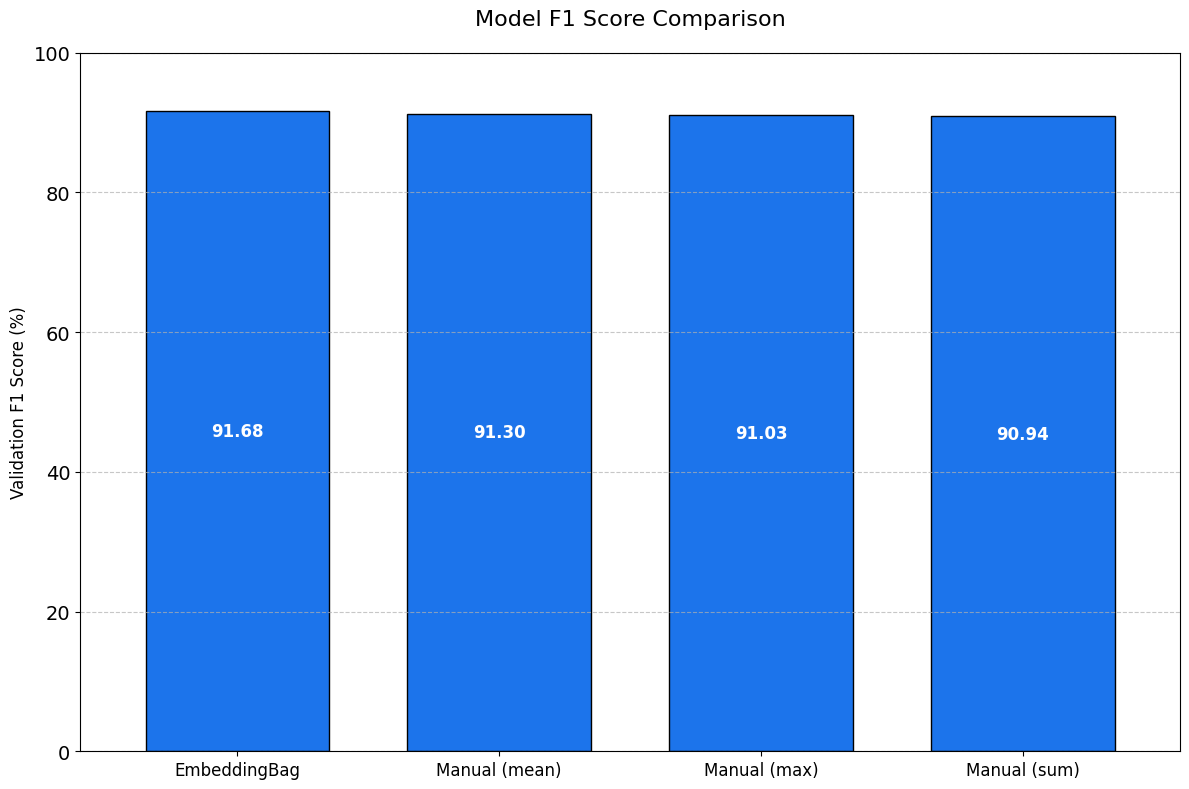

In [ ]:
best_model = helper_utils.plot_and_select_best_model(all_trained_data)

### Testing the Best Model on New Examples

You've done the heavy lifting: you trained multiple architectures and systematically selected the best model.

Now for the final test. It's time to see how your best model performs on completely new, unseen data. This is the best way to get a qualitative feel for how well your model has learned to generalize.

* Define a `test_products` list containing a mix of new recipe titles. This list includes straightforward examples as well as more challenging ones to see where the model excels and where it might struggle.
    * Feel free to add your own recipe titles to this list to test the model even further!

**Note**: Remember, the model's predictions are based *only* on the words in the recipe's `name`. It was never shown the ingredients list, so it has no knowledge of whether fruits or vegetables are the dominant ingredient. A recipe's name can sometimes be misleading, and the model's classification will reflect only what it has learned from the title's text.

In [ ]:
test_products = [
    "Blueberry Muffins",                  # Expected: Fruit
    "Spinach and Feta Stuffed Chicken",   # Expected: Vegetable
    "Classic Carrot Cake with Frosting",  # Expected: Vegetable
    "Tomato and Basil Bruschetta",        # Expected: Vegetable
    "Avocado Toast",                      # Expected: Fruit
    "Zucchini Bread with Walnuts",        # Expected: Vegetable
    "Lemon and Herb Roasted Chicken",     # Expected: Fruit
    "Strawberry Rhubarb Pie",             # Expected: Fruit
]

* Finally, loop through the `test_products` list to run the prediction for each recipe and see the model's final output.

In [ ]:
## Uncomment if you want to see the predict category function

# helper_utils.display_function(helper_utils.predict_category)

In [ ]:
# Loop through each test product
for product in test_products:
    # Call the prediction function with the required arguments
    category = helper_utils.predict_category(
        best_model,
        product,
        vocab,
        preprocess_text,
        device
    )
    # Print the results
    print(f"Product: '{product}'\nPredicted: {category}.\n")

Product: 'Blueberry Muffins'
Predicted: Fruit Recipe.

Product: 'Spinach and Feta Stuffed Chicken'
Predicted: Vegetable Recipe.

Product: 'Classic Carrot Cake with Frosting'
Predicted: Vegetable Recipe.

Product: 'Tomato and Basil Bruschetta'
Predicted: Vegetable Recipe.

Product: 'Avocado Toast'
Predicted: Fruit Recipe.

Product: 'Zucchini Bread with Walnuts'
Predicted: Vegetable Recipe.

Product: 'Lemon and Herb Roasted Chicken'
Predicted: Fruit Recipe.

Product: 'Strawberry Rhubarb Pie'
Predicted: Fruit Recipe.



## Conclusion

Congratulations on completing this lab! You have successfully navigated the entire pipeline for building a text classifier in PyTorch, moving from raw, unstructured text to a functional predictive model. This lab demonstrated how to translate the core concepts of text representation into a real-world application.

You began by carefully preprocessing the recipe data, building a vocabulary, and preparing `DataLoaders` that can handle the variable nature of text data, a key difference from working with fixed-size images. You implemented two distinct but related model architectures: one using the highly optimized `nn.EmbeddingBag` and another that allowed for manual control over different pooling strategies (`mean`, `max`, and `sum`). This comparison gave you direct insight into how different aggregation methods can impact performance.

Furthermore, you tackled the very common challenge of class imbalance by calculating and applying class weights, ensuring your model learned to classify both fruit and vegetable recipes effectively, rather than being biased toward the majority class. Finally, you systematically evaluated your models using the F1 score to identify the top performer and tested it on new, unseen data, which is the ultimate measure of a model's ability to generalize.

The model you built serves as an excellent baseline. The embeddings were trained from scratch on your specific dataset. The next logical step, which builds directly on these skills, is to leverage the power of **pre-trained embeddings**. Using vectors from models like GloVe or BERT, which have been trained on billions of words, can provide your model with a much richer understanding of language from the very start, often leading to significant performance gains.

这页 Conclusion 可以总结成 4 个核心点：

完成了完整的文本分类流程
从原始文本开始，做了预处理、建立 vocabulary、构造 DataLoader，最后训练出了可以进行预测的 PyTorch 文本分类模型。

比较了两类文本表示 / pooling 方法
你实现了：

nn.EmbeddingBag
nn.Embedding + manual pooling

手动 pooling 又比较了：

mean
max
sum

目的是观察不同的聚合方法对分类性能的影响。

处理了类别不平衡问题
因为 vegetable 样本明显多于 fruit，所以计算了 class weights，并把它传给 loss function：

nn.CrossEntropyLoss(weight=class_weights)

这样少数类 fruit 被预测错时，loss 惩罚更大，避免模型只偏向多数类。

对模型进行评估并选择最佳模型
使用 F1 score 等指标比较不同模型，然后用新的、没见过的数据测试最佳模型，检查它的泛化能力。

第一，变长文本怎么组织不同。EmbeddingBag 用 flatten + offsets，不需要 padding；另外三种 manual pooling 先把句子 padding 到同样长度，再用 mask 去掉 padding 的影响。

第二，pooling 是库帮你做，还是你自己显式控制不同。EmbeddingBag 把 Embedding + pooling 集成在一起，效率高、代码简单；manual 方式是 nn.Embedding → mask → pooling，更灵活，可以方便地替换 mean/max/sum 或以后设计更复杂的方法。

所以为什么要比较？主要是在验证两件事：

同一个文本分类任务里，不同的“变长序列处理方式”和“token → 句子向量的聚合方式”，会怎样影响性能和实现效率。